In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Putanja do CSV fajla
DATA_PATH = Path("../data/cars.csv")

# Učitavanje podataka
df = pd.read_csv(DATA_PATH)

# Prikaz prvih pet redova
df.head()

,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
0,mazda,2,5500,2008,with mileage,162000.0,petrol,1500.0,burgundy,mechanics,front-wheel drive,B
1,mazda,2,5350,2009,with mileage,120000.0,petrol,1300.0,black,mechanics,front-wheel drive,B
2,mazda,2,7000,2009,with mileage,61000.0,petrol,1500.0,silver,auto,front-wheel drive,B
3,mazda,2,3300,2003,with mileage,265000.0,diesel,1400.0,white,mechanics,front-wheel drive,B
4,mazda,2,5200,2008,with mileage,97183.0,diesel,1400.0,gray,mechanics,front-wheel drive,B


In [5]:
print("Broj redova i kolona:", df.shape)

Broj redova i kolona: (56244, 12)


In [6]:
df.columns.tolist()

['make',
 'model',
 'priceUSD',
 'year',
 'condition',
 'mileage(kilometers)',
 'fuel_type',
 'volume(cm3)',
 'color',
 'transmission',
 'drive_unit',
 'segment']

In [11]:
df.describe()

,priceUSD,year,mileage(kilometers),volume(cm3)
count,56244.000000,56244.000000,5.624400e+04,56197.000000
mean,7415.456440,2003.454840,2.443956e+05,2104.860615
std,8316.959261,8.144247,3.210307e+05,959.201633
min,48.000000,1910.000000,0.000000e+00,500.000000
25%,2350.000000,1998.000000,1.370000e+05,1600.000000
50%,5350.000000,2004.000000,2.285000e+05,1996.000000
75%,9807.500000,2010.000000,3.100000e+05,2300.000000
max,235235.000000,2019.000000,9.999999e+06,20000.000000


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56244 entries, 0 to 56243
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make                 56244 non-null  object 
 1   model                56244 non-null  object 
 2   priceUSD             56244 non-null  int64  
 3   year                 56244 non-null  int64  
 4   condition            56244 non-null  object 
 5   mileage(kilometers)  56244 non-null  float64
 6   fuel_type            56244 non-null  object 
 7   volume(cm3)          56197 non-null  float64
 8   color                56244 non-null  object 
 9   transmission         56244 non-null  object 
 10  drive_unit           54339 non-null  object 
 11  segment              50953 non-null  object 
dtypes: float64(2), int64(2), object(8)
memory usage: 5.1+ MB


In [13]:
missing_values = df.isnull().sum()

print("Nedostajuće vrednosti po kolonama:")
print(missing_values.sort_values(ascending=False))

Nedostajuće vrednosti po kolonama:
segment                5291
drive_unit             1905
volume(cm3)              47
make                      0
year                      0
priceUSD                  0
model                     0
condition                 0
fuel_type                 0
mileage(kilometers)       0
transmission              0
color                     0
dtype: int64


In [14]:
print("Broj nedostajućih cena:", df["priceUSD"].isnull().sum())
print("Najniža cena:", df["priceUSD"].min(), "USD")
print("Najviša cena:", df["priceUSD"].max(), "USD")
print("Prosečna cena:", round(df["priceUSD"].mean(), 2), "USD")
print("Medijalna cena:", df["priceUSD"].median(), "USD")

Broj nedostajućih cena: 0
Najniža cena: 48 USD
Najviša cena: 235235 USD
Prosečna cena: 7415.46 USD
Medijalna cena: 5350.0 USD


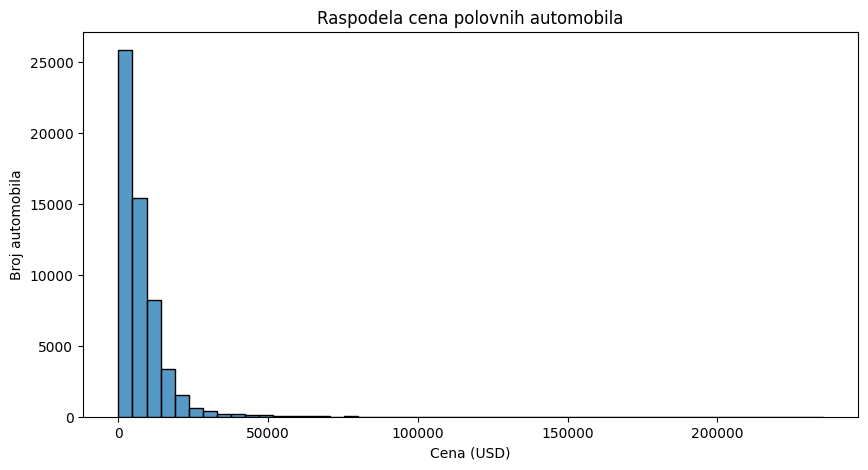

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="priceUSD", bins=50)

plt.title("Raspodela cena polovnih automobila")
plt.xlabel("Cena (USD)")
plt.ylabel("Broj automobila")

plt.show()

In [16]:
df["priceUSD"].describe()

count     56244.000000
mean       7415.456440
std        8316.959261
min          48.000000
25%        2350.000000
50%        5350.000000
75%        9807.500000
max      235235.000000
Name: priceUSD, dtype: float64

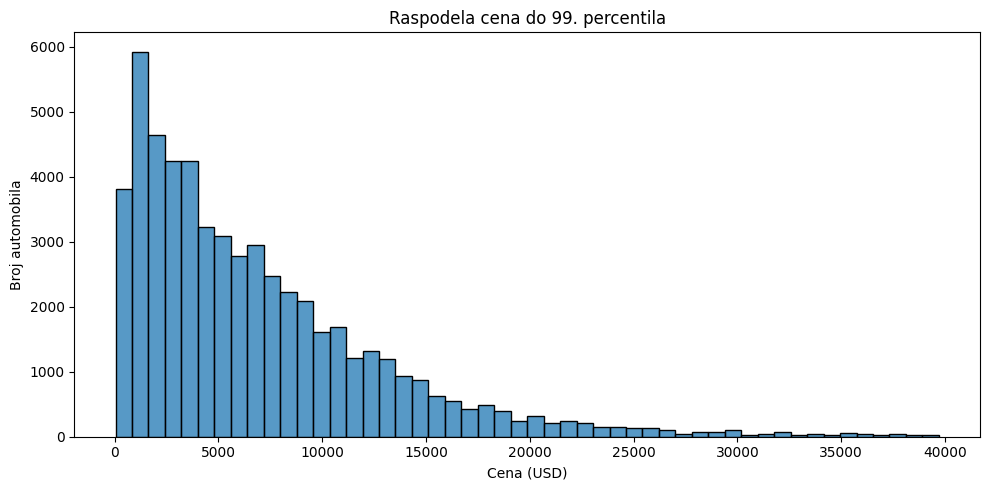

In [17]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df[df["priceUSD"] <= df["priceUSD"].quantile(0.99)],
    x="priceUSD",
    bins=50
)
plt.title("Raspodela cena do 99. percentila")
plt.xlabel("Cena (USD)")
plt.ylabel("Broj automobila")
plt.tight_layout()
plt.show()

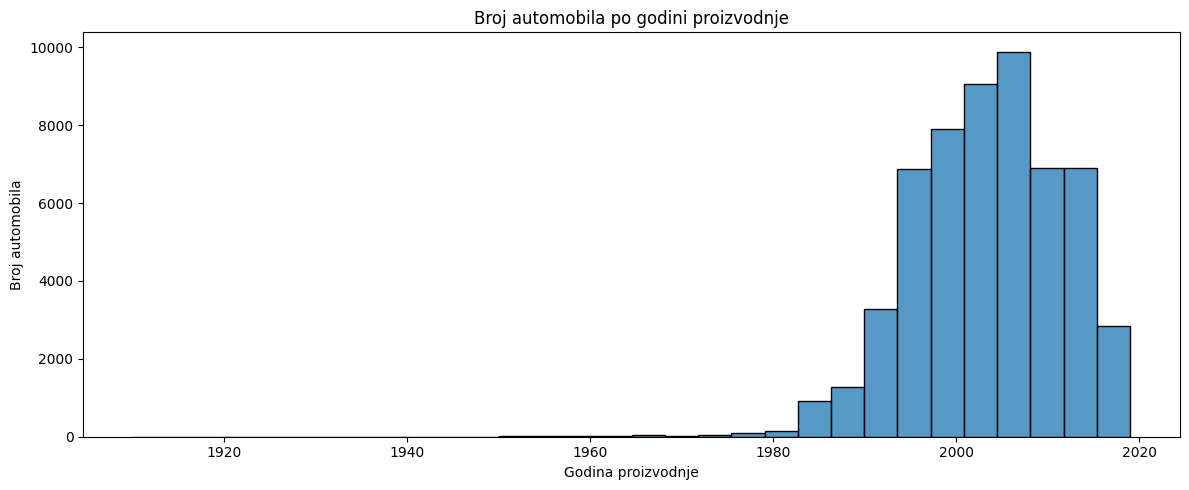

In [18]:
plt.figure(figsize=(12, 5))
sns.histplot(data=df, x="year", bins=30)
plt.title("Broj automobila po godini proizvodnje")
plt.xlabel("Godina proizvodnje")
plt.ylabel("Broj automobila")
plt.tight_layout()
plt.show()

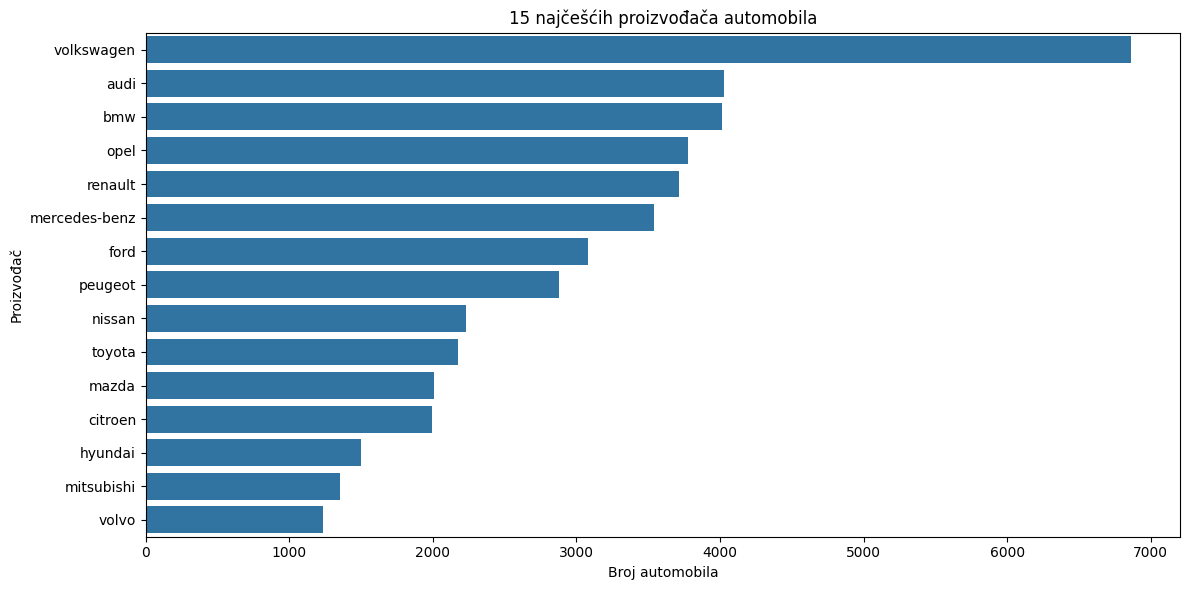

In [19]:
top_makes = df["make"].value_counts().head(15)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_makes.values, y=top_makes.index)
plt.title("15 najčešćih proizvođača automobila")
plt.xlabel("Broj automobila")
plt.ylabel("Proizvođač")
plt.tight_layout()
plt.show()

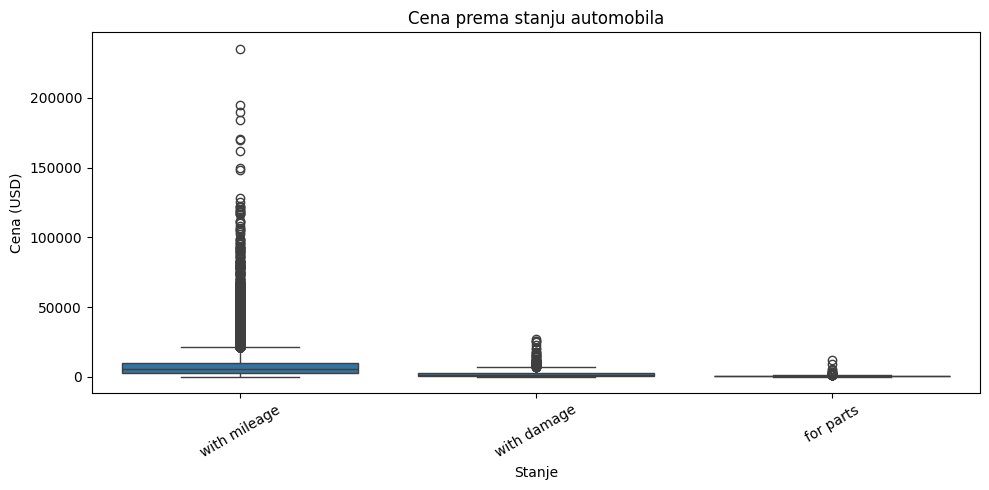

In [20]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="condition", y="priceUSD")
plt.title("Cena prema stanju automobila")
plt.xlabel("Stanje")
plt.ylabel("Cena (USD)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

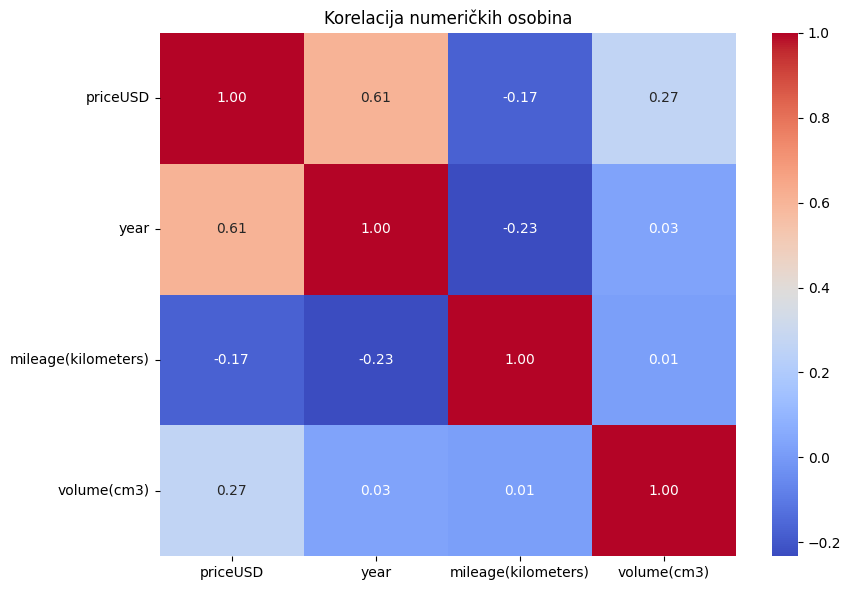

In [21]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(9, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Korelacija numeričkih osobina")
plt.tight_layout()
plt.show()